# Module 5 — Task 1: Predict future returns by various models

**Business problem (brief, verbatim):**
> NovaFin manages an equity portfolio. The investment committee wants to know: **Can ML identify stocks with superior future returns?**

**Task 1 (brief, verbatim):**
> **Task 1 —** predict future returns by various models

**Where this sits:** **forecast each stock's next-month return (this task)** → rank the stocks, pick the top ones and build a portfolio (Task 2) → Module 6 turns the predictions into optimised portfolios.

**Terms used throughout:**
- **Return:** the % change in price. ₹100 → ₹103 is a 3% return.
- **Next-month return (the target):** a stock's return from one month-end to the next (decision M5-01).
- **Walk-forward:** each month, train only on earlier months, predict the next month, then move forward one month. The model never sees the future.
- **IC (information coefficient):** each month, the rank correlation between predicted and actual returns across the 15 stocks, averaged over months. **−1** = exactly backwards, **0** = random, **+1** = perfect order. Higher is better; **0.03–0.05 is already useful** in real markets.
- **p:** the chance luck alone would give a result at least this strong. **Range 0 to 1;** small (below the line) = probably real, large = probably noise.
- **Macro (macroeconomic):** measures of the whole economy or market, not of one company: GDP growth, interest rate, VIX (the "fear index") and the market's return.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | The data, and what the macro columns really contain |
| 2 | Explore the data and engineer the inputs (decision M5-06) |
| 3 | The inputs the models get (decision M5-07) |
| 4 | Five ways of predicting, walk-forward over 43 test months (decision M5-08) |
| 5 | Does any model beat luck? The shuffled-returns test |
| 6 | Results compared |
| 7 | What an IC is worth in ₹ |
| 8 | What the results say |
| 9 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M5-01 target · M5-02 safe inputs · M5-03 monthly rebalancing · M5-04 walk-forward · M5-06 to M5-08 exploration, inputs, models · M5-10 hand-off.

## 0. Setup
Works locally and in Google Colab. Takes about 50 minutes, mostly the shuffled-returns test (step 5).

In [1]:
import os
import sys
import json
import itertools
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # stops a harmless Windows warning when the random forest uses all cores

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_05_equity_markets"
OUT_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb

from m05_data import (load_market, data_report, add_features, monthly_panel, MACRO_COLUMNS,
                      ALL_INPUTS, INPUTS, MACRO, INPUT_MEANINGS)
from m05_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42
TEST_START = pd.Timestamp("2023-01-01")     # first 24 months (Jan 2021 – Dec 2022) train only (M5-04)
N_SHUFFLES = 100                            # shuffled-returns runs per model (M5-08)
CRORE = 1e7
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def month_ic(pred: pd.Series, actual: pd.Series, dates: pd.Series) -> pd.Series:
    """IC for each month: Spearman rank correlation between predicted and actual returns
    across the 15 stocks that month. Returns one value per month.
    Predictions are matched to actual returns by row label (stock and month), not by position."""
    pred = pred.reindex(actual.index)
    frame = pd.DataFrame({"p": pred.values, "y": actual.values, "d": dates.reindex(actual.index).values})
    return frame.groupby("d").apply(lambda x: stats.spearmanr(x.p, x.y).correlation if x.p.nunique() > 1 else np.nan)


def t_test_p(values) -> float:
    """p for 'the average is really different from 0' (two-sided t-test over months)."""
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    return float(stats.ttest_1samp(v, 0).pvalue)


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Outputs go to: module_05_equity_markets/outputs/task1


## 1. The data, and what the macro columns really contain

**Checks:** rows, gaps, dates, and that `Return` is today's price change (so predicting it would be leakage: using information not available in advance; decision M5-01).

**The macro columns, tested:** in real life each is **one number for everyone on a given day** that changes **slowly** (GDP is published once a quarter). Two checks:
- **How many different values on the same date?** Real macro data: 1.
- **Correlation with the day before** (−1 to +1): real macro data is close to **+1** (today's value is almost yesterday's); random numbers give about **0**.

Also: does `Market_Return` move with the 15 stocks? A real market index correlates about +0.6 to +0.9 with the average stock. And do the stocks move with each other? Real large-caps: about 0.3–0.5.

In [2]:
mkt = load_market()
for k, v in data_report(mkt).items():
    print(f"{k}: {v}")

rows = []
for c in MACRO_COLUMNS:
    wide = mkt.pivot(index="Date", columns="Ticker", values=c)
    rows.append({"Column": c, "Different values on the same date (max)": int(mkt.groupby("Date")[c].nunique().max()),
                 "Correlation with the day before (average over stocks)": np.mean([wide[t].autocorr() for t in wide]),
                 "Range": f"{mkt[c].min():.2f} to {mkt[c].max():.2f}"})
macro_check = pd.DataFrame(rows)
daily = mkt.pivot(index="Date", columns="Ticker", values="Return")
avg_stock = daily.mean(axis=1)
mkt_col = mkt.groupby("Date").Market_Return.mean()
corr_mkt = np.corrcoef(avg_stock, mkt_col)[0, 1]
pair_corr = daily.corr().values[np.triu_indices(15, 1)].mean()
print(f"\nMarket_Return vs the 15 stocks' average return, same day: correlation {corr_mkt:+.3f} (a real index: about +0.6 to +0.9)")
print(f"Average correlation between two stocks' daily returns: {pair_corr:+.3f} (real large-caps: about 0.3 to 0.5)")
display(macro_check.round(3))

rows: 21855
missing_values: 0
duplicate_rows: 0
tickers: 15
rows_per_ticker: [1457]
date_range: ('2021-01-29', '2026-08-31')
sectors: ['Auto', 'Banking', 'Consumer', 'Energy', 'Healthcare', 'IT', 'Industrials', 'Telecom']
Return_is_same_day_close_to_close: True
month_end_rebalance_dates: 68



Market_Return vs the 15 stocks' average return, same day: correlation -0.016 (a real index: about +0.6 to +0.9)
Average correlation between two stocks' daily returns: +0.004 (real large-caps: about 0.3 to 0.5)


,Column,Different values on the same date (max),Correlation with the day before (average over stocks),Range
0,Market_Return,15,-0.003,-0.05 to 0.05
1,GDP_Growth,15,0.009,3.79 to 9.52
2,Interest_Rate,15,-0.004,3.63 to 9.30
3,VIX,15,-0.008,8.00 to 36.60


## 2. Explore the data and engineer the inputs (decision M5-06)

### 2a. The target: balanced? extreme months?
- **Balance:** the share of up vs down months. Balancing only matters when one outcome is rare (in a yes/no problem).
- **Extreme months:** returns more than 3 typical swings (standard deviations, sd) from the average. A bell curve gives about 0.27% of values that far out.

In [3]:
panel = monthly_panel(mkt)                      # one row per stock per month-end with a next month
y = panel.Next_Month_Return
n_months = panel.Date.nunique()
print(f"Rows: {len(panel):,} = {n_months} months × {panel.Ticker.nunique()} stocks "
      f"(68 month-ends − 1, because the last month-end has no month after it)")
z = (y - y.mean()) / y.std()
target = {"up_share": float((y > 0).mean()), "mean": float(y.mean()), "sd": float(y.std()),
          "min": float(y.min()), "max": float(y.max()), "beyond_3sd": int((z.abs() > 3).sum()),
          "expected_beyond_3sd": len(y) * 0.0027, "skew": float(stats.skew(y)), "excess_kurtosis": float(stats.kurtosis(y)),
          "sd_between_stocks": float(panel.groupby("Date").Next_Month_Return.std().mean()),
          "sd_of_monthly_average": float(panel.groupby("Date").Next_Month_Return.mean().std())}
print(f"Up months {target['up_share']:.1%}, down {1 - target['up_share']:.1%}  → nearly balanced, no balancing needed")
print(f"Average {target['mean']:.2%} a month; typical swing (sd) ±{target['sd']:.2%}; range {target['min']:.1%} to {target['max']:.1%}")
print(f"Beyond 3 sd: {target['beyond_3sd']} of {len(y):,} (a bell curve gives about {target['expected_beyond_3sd']:.1f})")
print(f"Lopsidedness (skew, 0 = symmetric) {target['skew']:.2f}; fat tails (excess kurtosis, 0 = bell curve) {target['excess_kurtosis']:.2f}")
print(f"Spread between stocks in the same month (average sd) {target['sd_between_stocks']:.2%}; "
      f"spread of the 15-stock average from month to month {target['sd_of_monthly_average']:.2%}")

Rows: 1,005 = 67 months × 15 stocks (68 month-ends − 1, because the last month-end has no month after it)
Up months 54.8%, down 45.2%  → nearly balanced, no balancing needed
Average 1.17% a month; typical swing (sd) ±8.64%; range -22.1% to 31.6%
Beyond 3 sd: 2 of 1,005 (a bell curve gives about 2.7)
Lopsidedness (skew, 0 = symmetric) 0.14; fat tails (excess kurtosis, 0 = bell curve) 0.03
Spread between stocks in the same month (average sd) 8.52%; spread of the 15-stock average from month to month 2.16%


### 2b. Each of the 22 inputs against future return, at three horizons

**The 22 inputs** (all known at the close of the day; formulas in `helpers/m05_data.py`):
- **price history:** past 1, 5, 20, 60, 120, 250-day returns; `Momentum_20D` (given); distance from the 50-day average; RSI (0–100 gauge of recent up vs down days);
- **risk:** 20-day (given) and 60-day volatility (how much daily returns swing);
- **trading:** volume vs its 60-day normal; the day's high–low range; the overnight gap;
- **macro:** the four macro columns, raw and as 20-day averages.

**The test:** the IC of each input against the next **day's**, **week's** (5 trading days) and **month's** return. Days and weeks are measured on Fridays.

```text
Tests = 22 inputs × 3 horizons = 66
Line  = 0.05 ÷ 66 = 0.0008      (0.05 = the usual 1-in-20 line; divided by the number of tests so that
                                 across all 66 the chance of even one false "hit" stays about 1 in 20)
```

In [4]:
feats = add_features(mkt)
g = mkt.groupby("Ticker")
feats["y_1D"] = g.Close.shift(-1) / mkt.Close - 1          # next day's return
feats["y_5D"] = g.Close.shift(-5) / mkt.Close - 1          # next week's return
fridays = feats[feats.Date.dt.dayofweek == 4]


def input_ic(frame, inp, tgt):
    v = month_ic(frame[inp], frame[tgt], frame.Date).dropna()
    return v.mean(), t_test_p(v)


rows = []
for inp in ALL_INPUTS:
    r = {"Input": inp, "Group": "Macro" if inp in MACRO else ("Given" if inp in ("Momentum_20D", "Volatility_20D") else "Price / trading")}
    for label, frame, tgt in [("next day", fridays, "y_1D"), ("next week", fridays, "y_5D"), ("next month", panel, "Next_Month_Return")]:
        r[f"IC {label}"], r[f"p {label}"] = input_ic(frame, inp, tgt)
    rows.append(r)
input_tests = pd.DataFrame(rows)
N_TESTS = len(ALL_INPUTS) * 3
LINE_INPUTS = 0.05 / N_TESTS
pcols = [c for c in input_tests if c.startswith("p ")]
input_tests["Smallest p"] = input_tests[pcols].min(axis=1)
input_tests["Passes the line"] = np.where(input_tests["Smallest p"] < LINE_INPUTS, "Yes", "No")
print(f"Tests: {len(ALL_INPUTS)} inputs × 3 horizons = {N_TESTS}; line = 0.05 ÷ {N_TESTS} = {LINE_INPUTS:.4f}")
print(f"Passing: {(input_tests['Passes the line'] == 'Yes').sum()} of {len(ALL_INPUTS)} inputs;  smallest p anywhere {input_tests['Smallest p'].min():.3f}")
display(input_tests.round(3))

Tests: 22 inputs × 3 horizons = 66; line = 0.05 ÷ 66 = 0.0008
Passing: 0 of 22 inputs;  smallest p anywhere 0.019


,Input,Group,IC next day,p next day,IC next week,p next week,IC next month,p next month,Smallest p,Passes the line
0,Past_1D,Price / trading,0.011,0.494,-0.000,0.988,-0.026,0.423,0.423,No
1,Past_5D,Price / trading,0.020,0.187,-0.005,0.782,-0.030,0.410,0.187,No
2,Past_20D,Price / trading,0.016,0.290,0.010,0.555,-0.002,0.937,0.290,No
3,Past_60D,Price / trading,0.023,0.158,-0.011,0.516,-0.019,0.597,0.158,No
4,Past_120D,Price / trading,0.013,0.459,-0.024,0.141,-0.039,0.266,0.141,No
5,Past_250D,Price / trading,0.022,0.274,-0.024,0.175,-0.053,0.146,0.146,No
6,Volatility_60D,Price / trading,0.004,0.799,0.011,0.500,0.038,0.260,0.260,No
7,Dist_MA50,Price / trading,0.016,0.298,-0.007,0.685,-0.041,0.250,0.250,No
8,RSI_14,Price / trading,0.001,0.958,0.005,0.753,0.000,0.993,0.753,No
9,Volume_z,Price / trading,-0.004,0.799,-0.014,0.398,0.014,0.614,0.398,No


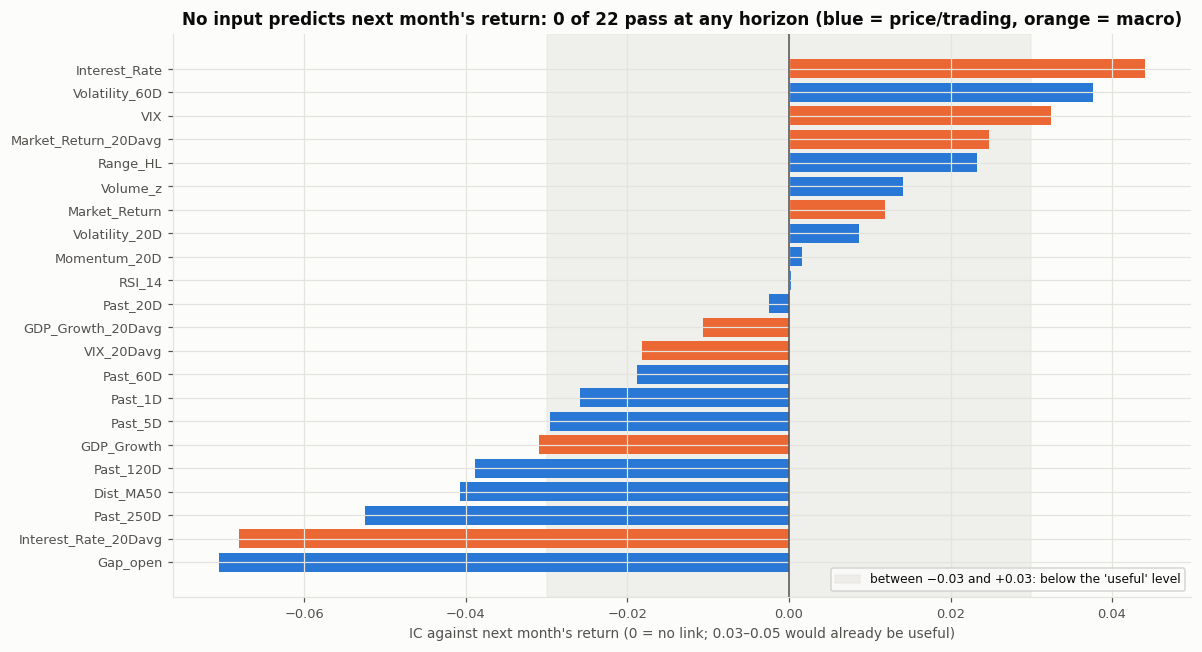

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
order = input_tests.sort_values("IC next month")
colours = [ORANGE if gr == "Macro" else BLUE for gr in order.Group]
ax.barh(order.Input, order["IC next month"], color=colours)
ax.axvline(0, color=INK_2, lw=1)
ax.axvspan(-0.03, 0.03, color=GRID, alpha=0.5, zorder=0, label="between −0.03 and +0.03: below the 'useful' level")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("IC against next month's return (0 = no link; 0.03–0.05 would already be useful)")
ax.set_title(f"No input predicts next month's return: 0 of {len(ALL_INPUTS)} pass at any horizon (blue = price/trading, orange = macro)")
fig.tight_layout(); save_chart(fig, "01_input_tests"); plt.show()

### 2c. The inputs against each other
Correlation between two inputs (−1 to +1): near ±1 means they carry the same information.

Strongest pairs:
  Past_20D ~ Momentum_20D: +1.00
  Past_20D ~ Dist_MA50: +0.87
  Dist_MA50 ~ Momentum_20D: +0.87
  RSI_14 ~ Momentum_20D: +0.83
  Past_20D ~ RSI_14: +0.83
  Dist_MA50 ~ RSI_14: +0.79
Largest correlation among the given columns: 0.072


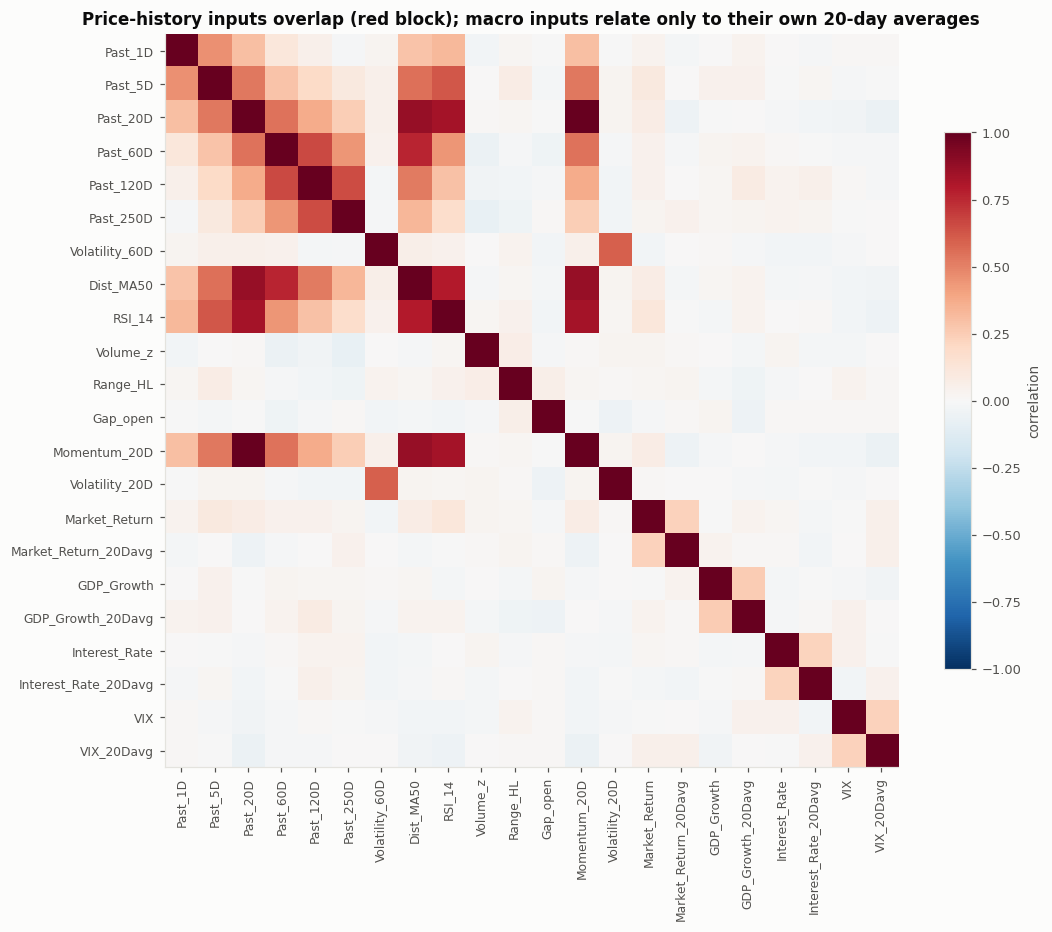

In [6]:
corr = panel[ALL_INPUTS].corr()
pairs = sorted(((a, b, corr.loc[a, b]) for a, b in itertools.combinations(ALL_INPUTS, 2)), key=lambda x: -abs(x[2]))
print("Strongest pairs:")
for a, b, v in pairs[:6]:
    print(f"  {a} ~ {b}: {v:+.2f}")
given_cols = ["Momentum_20D", "Volatility_20D"] + MACRO_COLUMNS
gc = panel[given_cols].corr().abs().values
np.fill_diagonal(gc, 0)
print(f"Largest correlation among the given columns: {gc.max():.3f}")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_INPUTS)), ALL_INPUTS, rotation=90, fontsize=8)
ax.set_yticks(range(len(ALL_INPUTS)), ALL_INPUTS, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlation")
ax.set_title("Price-history inputs overlap (red block); macro inputs relate only to their own 20-day averages")
fig.tight_layout(); save_chart(fig, "02_input_correlations"); plt.show()

### 2d. Sector, calendar month, and market mood
**Kruskal-Wallis test:** do several groups have different typical returns? p below 0.05 = yes.
**Mann-Whitney test:** the same question for two groups.

In [7]:
sec = panel.groupby("Sector").Next_Month_Return.mean()
p_sector = stats.kruskal(*[x.Next_Month_Return for _, x in panel.groupby("Sector")]).pvalue
p_month = stats.kruskal(*[x.Next_Month_Return for _, x in panel.groupby(panel.Date.dt.month)]).pvalue
hi = panel.VIX_20Davg > panel.VIX_20Davg.median()
p_vix = stats.mannwhitneyu(panel.Next_Month_Return[hi], panel.Next_Month_Return[~hi]).pvalue
print("Average monthly return by sector:", ", ".join(f"{k} {v:.2%}" for k, v in sec.sort_values().items()))
print(f"Do sectors differ?        p = {p_sector:.2f}")
print(f"Do calendar months differ? p = {p_month:.2f}")
print(f"High vs low VIX months: {panel.Next_Month_Return[hi].mean():.2%} vs {panel.Next_Month_Return[~hi].mean():.2%}, p = {p_vix:.2f}")

Average monthly return by sector: Telecom 0.11%, Industrials 0.30%, Auto 0.97%, Banking 1.18%, Consumer 1.19%, Healthcare 1.44%, IT 1.61%, Energy 2.00%
Do sectors differ?        p = 0.96
Do calendar months differ? p = 0.73
High vs low VIX months: 0.91% vs 1.42%, p = 0.40


### 2e. Combinations: "stocks that are X **and** Y"
Each month, mark the top and bottom third of every input (44 conditions), then test **every pair** of conditions: do stocks meeting both beat that month's 15-stock average?

**Why a shuffle test:** searching hundreds of pairs, one always looks good by luck. So the same search is repeated with each month's returns shuffled among the stocks (breaking any real link) 100 times, to see what the best pair looks like on pure luck.

```text
p = (number of shuffled searches whose best pair ≥ the real best pair + 1) ÷ (100 + 1)
```

In [8]:
d = panel.dropna(subset=ALL_INPUTS).reset_index(drop=True)
cond_names, cond_rows = [], []
for inp in ALL_INPUTS:
    r = d.groupby("Date")[inp].rank(pct=True)                    # rank within the month
    cond_names += [f"{inp} top third", f"{inp} bottom third"]
    cond_rows += [(r > 2 / 3).values, (r <= 1 / 3).values]
COND = np.array(cond_rows)
excess = (d.Next_Month_Return - d.groupby("Date").Next_Month_Return.transform("mean")).values   # vs month's average
month_idx = list(d.groupby("Date").indices.values())


def best_pair(e, min_size=40):
    best = (-np.inf, None, 0)
    for i, j in itertools.combinations(range(len(cond_names)), 2):
        m = COND[i] & COND[j]
        n = m.sum()
        if n >= min_size:
            v = e[m].mean()
            if v > best[0]:
                best = (v, (cond_names[i], cond_names[j]), n)
    return best


combo_val, combo_pair, combo_n = best_pair(excess)
mask = COND[cond_names.index(combo_pair[0])] & COND[cond_names.index(combo_pair[1])]
naive_p = stats.ttest_1samp(excess[mask], 0).pvalue
rng = np.random.default_rng(SEED)
null = []
for _ in range(N_SHUFFLES):
    e2 = excess.copy()
    for idx in month_idx:
        e2[idx] = rng.permutation(e2[idx])                        # shuffle returns among stocks, within each month
    null.append(best_pair(e2)[0])
combo_p = (1 + sum(v >= combo_val for v in null)) / (N_SHUFFLES + 1)
n_pairs = len(cond_names) * (len(cond_names) - 1) // 2
print(f"Rows {len(d):,} (months where all 22 inputs exist); conditions {len(cond_names)}; pairs tested {n_pairs:,}")
print(f"Best pair: {combo_pair[0]} AND {combo_pair[1]}: {combo_n} stock-months, beat the month's average by {combo_val:.2%} a month")
print(f"Tested on its own: p = {naive_p:.3f}")
print(f"Best pair on shuffled returns: average {np.mean(null):.2%}, 95th percentile {np.percentile(null, 95):.2%} → p = {combo_p:.2f}")

Rows 825 (months where all 22 inputs exist); conditions 44; pairs tested 946
Best pair: Past_250D bottom third AND GDP_Growth bottom third: 86 stock-months, beat the month's average by 2.73% a month
Tested on its own: p = 0.012
Best pair on shuffled returns: average 2.71%, 95th percentile 3.26% → p = 0.48


## 3. The inputs the models get (decision M5-07)

- **Dropped: the 8 macro inputs.** Step 1 shows they're random numbers, not economic data (a different value for each stock on the same date, about 0 correlation with the day before). The reason is what they *are*, not a test score.
- **Dropped: `Past_20D`,** identical to the given `Momentum_20D` (correlation 1.00).
- **Kept: 13 inputs + sector** (8 yes/no columns). The models handle the remaining overlaps: ridge shares weight across overlapping inputs, trees pick one.
- **Check:** ridge and LightGBM are also run once on **all 22 inputs**, to show what the macro columns do.

**Early months:** the 250-day return exists only from Jan 2022, the 120-day from Jul 2021. Missing early values are filled with the training months' median (a neutral value), so the first 24 months still train the models. Every model is tested on the same 43 months.

In [9]:
SECTOR_COLS = [c for c in panel if c.startswith("Sec_")]
X_COLS = INPUTS + SECTOR_COLS
print(f"Inputs: {len(INPUTS)} + {len(SECTOR_COLS)} sector columns = {len(X_COLS)}")
display(pd.DataFrame({"Input": INPUTS, "Meaning": [INPUT_MEANINGS[c] for c in INPUTS]}))

Inputs: 13 + 8 sector columns = 21


,Input,Meaning
0,Past_1D,return over the last day
1,Past_5D,return over the last week (5 trading days)
2,Past_60D,return over the last 3 months (60 trading days)
3,Past_120D,return over the last 6 months (120 trading days)
4,Past_250D,return over the last year (250 trading days)
5,Volatility_60D,how much daily returns swung over 60 days
6,Dist_MA50,how far the price is above (+) or below (−) it...
7,RSI_14,relative strength index: 0–100 gauge of recent...
8,Volume_z,"today's trading volume vs its 60-day normal, i..."
9,Range_HL,"today's high minus low, as a share of the clos..."


## 4. Five ways of predicting, walk-forward over 43 test months (decision M5-08)

```text
Test months = 67 months with a next month − 24 training-only months = 43   (Jan 2023 – Jul 2026)
Each test month: train on every earlier month, predict all 15 stocks, compare with what happened
Test predictions = 43 × 15 = 645
```

| Way of predicting | What it does | Settings, and why |
| --- | --- | --- |
| **Predict zero** (benchmark) | Every stock gets 0% | "Know nothing" |
| **Past average** (benchmark) | Each stock's average monthly return so far | "History repeats" |
| **Linear regression** | A weighted sum of the inputs | None to set |
| **Ridge regression** | Linear, with the weights kept small so it doesn't chase noise | Penalty 10 (moderate: noisy data needs restraint) |
| **Random forest** | 200 decision trees on random samples, averaged | At least 20 stock-months per end box: a training window has 360–960 stock-months, so trees can't memorise single months |
| **LightGBM** | Small trees built one after another, each fixing the last one's errors | 200 trees, 4 end boxes each, learning rate 0.05 (each tree changes the prediction a little), at least 20 per box |

**Measures** (IC decides, because Task 2 ranks stocks):

| Measure | In plain words | Good |
| --- | --- | --- |
| **IC** | Does the model put the 15 stocks in the right order each month? | Higher; −1 to +1, 0 = random |
| **RMSE** | Typical error, in % return; big misses count extra | Lower |
| **MAE** | Plain average error, in % return | Lower |
| **Hit rate** | How often the direction (up or down) is right | Higher, **compared with "always up"** (the share of up months), not 50% |

In [10]:
MODEL_NAMES = ["Linear regression", "Ridge regression", "Random forest", "LightGBM"]


def make_model(name):
    """A fresh, untrained model with the agreed settings (M5-08)."""
    if name == "Linear regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
    if name == "Ridge regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))
    if name == "Random forest":
        return make_pipeline(SimpleImputer(strategy="median"),
                             RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED))
    return lgb.LGBMRegressor(n_estimators=200, num_leaves=4, learning_rate=0.05, min_child_samples=20,
                             random_state=SEED, verbose=-1)


TEST_DATES = sorted(panel.Date[panel.Date >= TEST_START].unique())
print(f"Test months: {len(TEST_DATES)} ({pd.Timestamp(TEST_DATES[0]):%b %Y} – {pd.Timestamp(TEST_DATES[-1]):%b %Y})")


def walk_forward(name, cols, data):
    """Each test month: train on all earlier months, predict that month. Returns predictions
    for the test rows (same order as data[data.Date >= TEST_START])."""
    out = []
    for dt in TEST_DATES:
        train, test = data[data.Date < dt], data[data.Date == dt]
        if name == "Predict zero":
            p = np.zeros(len(test))
        elif name == "Past average":
            p = test.Ticker.map(train.groupby("Ticker").Next_Month_Return.mean()).values
        else:
            p = make_model(name).fit(train[cols], train.Next_Month_Return).predict(test[cols])
        out.append(pd.Series(p, index=test.index))
    return pd.concat(out).sort_index()                # same row order as the data


test_rows = panel[panel.Date >= TEST_START]
start = time.time()
preds = {name: walk_forward(name, X_COLS, panel) for name in ["Predict zero", "Past average"] + MODEL_NAMES}
check_cols = ALL_INPUTS + SECTOR_COLS
preds["Ridge regression, all 22 inputs"] = walk_forward("Ridge regression", check_cols, panel)
preds["LightGBM, all 22 inputs"] = walk_forward("LightGBM", check_cols, panel)
print(f"Walk-forward done in {time.time() - start:.0f} s; {len(test_rows)} test predictions per model")

Test months: 43 (Jan 2023 – Jul 2026)


Walk-forward done in 47 s; 645 test predictions per model


In [11]:
UP_SHARE = float((test_rows.Next_Month_Return > 0).mean())


def measures(name):
    yy = test_rows.Next_Month_Return
    p = preds[name].reindex(yy.index)                 # match each prediction to its stock and month
    ic = month_ic(p, yy, test_rows.Date) if name != "Predict zero" else pd.Series([np.nan])
    return {"Model": name, "IC": ic.mean(), "IC p (t-test)": t_test_p(ic) if name != "Predict zero" else np.nan,
            "Months IC > 0": (ic > 0).mean() if name != "Predict zero" else np.nan,
            "RMSE": np.sqrt(((p - yy) ** 2).mean()), "MAE": (p - yy).abs().mean(),
            "Hit rate": (np.sign(p) == np.sign(yy)).mean() if name != "Predict zero" else np.nan,
            "Hit rate of 'always up'": UP_SHARE}, ic


results, monthly_ics = [], {}
for name in preds:
    r, ic = measures(name)
    results.append(r)
    monthly_ics[name] = ic
results = pd.DataFrame(results)
print(f"'Always up' hit rate = share of up stock-months in the test period = {UP_SHARE:.1%}")
display(results.style.format({"IC": "{:+.3f}", "IC p (t-test)": "{:.2f}", "Months IC > 0": "{:.0%}", "RMSE": "{:.2%}",
                              "MAE": "{:.2%}", "Hit rate": "{:.1%}", "Hit rate of 'always up'": "{:.1%}"}, na_rep="—"))

'Always up' hit rate = share of up stock-months in the test period = 55.0%


,Model,IC,IC p (t-test),Months IC > 0,RMSE,MAE,Hit rate,Hit rate of 'always up'
0,Predict zero,—,—,—,8.67%,6.89%,—,55.0%
1,Past average,-0.002,0.96,42%,8.65%,6.91%,52.7%,55.0%
2,Linear regression,+0.005,0.92,56%,8.74%,6.91%,52.9%,55.0%
3,Ridge regression,+0.004,0.93,53%,8.73%,6.91%,54.0%,55.0%
4,Random forest,-0.049,0.35,37%,8.77%,6.92%,53.3%,55.0%
5,LightGBM,-0.015,0.70,49%,8.94%,7.08%,52.6%,55.0%
6,"Ridge regression, all 22 inputs",-0.007,0.86,49%,8.77%,6.94%,54.9%,55.0%
7,"LightGBM, all 22 inputs",-0.003,0.93,53%,8.92%,7.05%,52.9%,55.0%


## 5. Does any model beat luck? The shuffled-returns test (decision M5-08)

For each model: shuffle each month's returns among the 15 stocks (keeping the month's overall market move, breaking any link between inputs and which stock does well), run the full walk-forward, and record the IC. Repeat 100 times.

```text
p    = (number of shuffled runs with IC ≥ the real IC + 1) ÷ (100 + 1)
Line = 0.05 ÷ 4 models = 0.0125     (smallest possible p = 1 ÷ 101 = 0.0099, so a real edge could pass)
```

In [12]:
LINE_MODELS = 0.05 / len(MODEL_NAMES)
rng = np.random.default_rng(SEED)
shuffled = {name: [] for name in MODEL_NAMES}
start = time.time()
for run in range(N_SHUFFLES):
    sh = panel.copy()
    sh["Next_Month_Return"] = sh.groupby("Date").Next_Month_Return.transform(lambda s: rng.permutation(s.values))
    sh_test = sh[sh.Date >= TEST_START]
    for name in MODEL_NAMES:
        p = walk_forward(name, X_COLS, sh)
        shuffled[name].append(month_ic(p, sh_test.Next_Month_Return, sh_test.Date).mean())
    if run == 0:
        print(f"one run takes {time.time() - start:.0f} s; {N_SHUFFLES} runs ≈ {N_SHUFFLES * (time.time() - start) / 60:.0f} min")
print(f"Shuffled test done in {(time.time() - start) / 60:.0f} min")

rows = []
for name in MODEL_NAMES:
    real = results.set_index("Model").loc[name, "IC"]
    null = np.array(shuffled[name])
    p = (1 + (null >= real).sum()) / (N_SHUFFLES + 1)
    rows.append({"Model": name, "IC": real, "Luck: 95% range low": np.percentile(null, 2.5),
                 "Luck: 95% range high": np.percentile(null, 97.5), "p (shuffled)": p,
                 "Beats luck?": "Yes" if p < LINE_MODELS else "No"})
shuffle_tests = pd.DataFrame(rows)
print(f"Line: 0.05 ÷ {len(MODEL_NAMES)} = {LINE_MODELS:.4f}")
display(shuffle_tests.style.format({"IC": "{:+.3f}", "Luck: 95% range low": "{:+.3f}", "Luck: 95% range high": "{:+.3f}",
                                    "p (shuffled)": "{:.2f}"}))

one run takes 35 s; 100 runs ≈ 59 min


Shuffled test done in 50 min
Line: 0.05 ÷ 4 = 0.0125


,Model,IC,Luck: 95% range low,Luck: 95% range high,p (shuffled),Beats luck?
0,Linear regression,+0.005,-0.076,+0.079,0.53,No
1,Ridge regression,+0.004,-0.075,+0.077,0.53,No
2,Random forest,-0.049,-0.074,+0.080,0.93,No
3,LightGBM,-0.015,-0.083,+0.076,0.64,No


## 6. Results compared

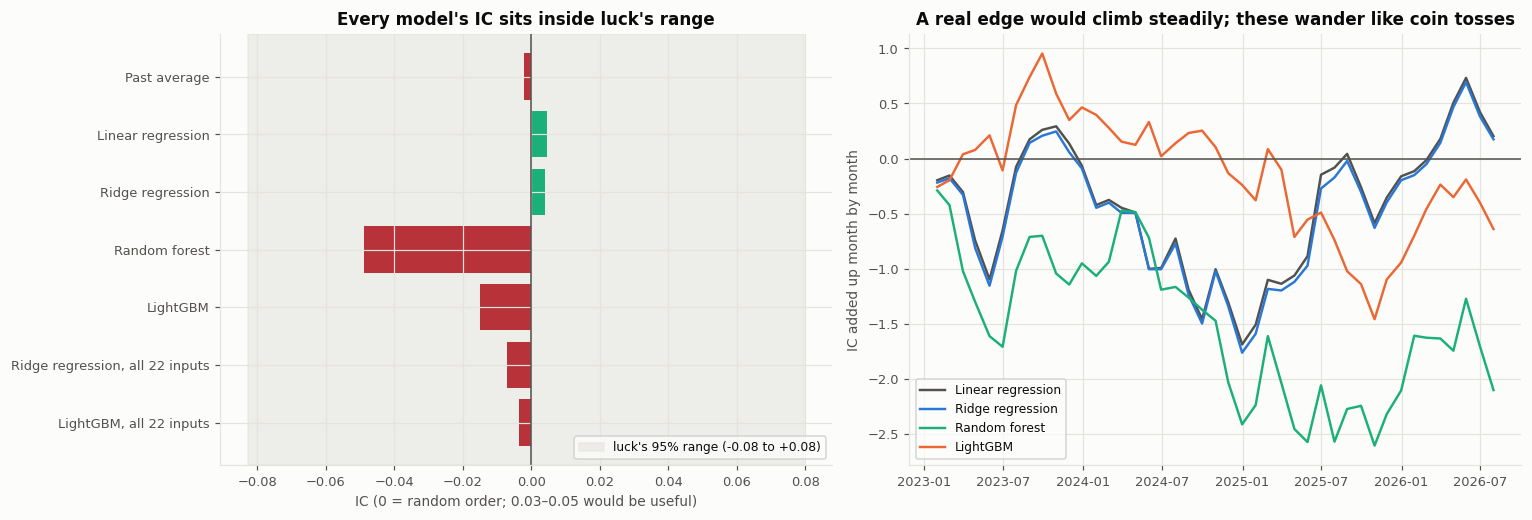

Verdict: are returns predictable from this data? No: no model beats luck


In [13]:
model_tests = results.merge(shuffle_tests[["Model", "Luck: 95% range low", "Luck: 95% range high", "p (shuffled)", "Beats luck?"]],
                            on="Model", how="left")
PREDICTABLE = bool((shuffle_tests["Beats luck?"] == "Yes").any())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
names = ["Past average"] + MODEL_NAMES + ["Ridge regression, all 22 inputs", "LightGBM, all 22 inputs"]
vals = model_tests.set_index("Model").loc[names, "IC"]
ax.barh(names[::-1], vals[::-1], color=[GAIN if v > 0 else LOSS for v in vals[::-1]])
lo, hi = shuffle_tests["Luck: 95% range low"].min(), shuffle_tests["Luck: 95% range high"].max()
ax.axvspan(lo, hi, color=GRID, alpha=0.6, zorder=0, label=f"luck's 95% range ({lo:+.2f} to {hi:+.2f})")
ax.axvline(0, color=INK_2, lw=1)
ax.set_xlabel("IC (0 = random order; 0.03–0.05 would be useful)")
ax.set_title("Every model's IC sits inside luck's range")
ax.legend(loc="lower right", fontsize=8)
ax = axes[1]
for name, col in zip(MODEL_NAMES, [INK_2, BLUE, AQUA, ORANGE]):
    ic = monthly_ics[name]
    ax.plot(pd.to_datetime(ic.index), ic.cumsum(), label=name, color=col, lw=1.6)
ax.axhline(0, color=INK_2, lw=1)
ax.set_ylabel("IC added up month by month")
ax.set_title("A real edge would climb steadily; these wander like coin tosses")
ax.legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "03_models_vs_luck"); plt.show()
print("Verdict: are returns predictable from this data?", "Yes" if PREDICTABLE else "No: no model beats luck")

## 7. What an IC is worth in ₹

A rule of thumb links an IC to money. If a model ranks stocks with IC = r, the stocks it ranks highest beat the average by roughly:

```text
Extra return of the top 5 a month ≈ IC × spread of returns between stocks × average score of the top 5
  spread between stocks  = the typical gap between stocks in the same month (step 2a: about 8.5%)
  average score of top 5 = how far above average, in typical gaps, the best 5 of 15 sit (worked out below: about 1.03)
```

**Example:** IC 0.05 → 0.05 × 8.5% × 1.03 ≈ 0.44% a month ≈ 5.3% a year. On ₹100 crore, that's about ₹5.3 crore a year, before trading costs. That is why an IC of 0.03–0.05 counts as useful. Task 2 measures the real portfolio return directly.

In [14]:
rng = np.random.default_rng(SEED)
TOP5_SCORE = float(np.sort(rng.standard_normal((200_000, 15)), axis=1)[:, -5:].mean())   # average of the best 5 of 15
SPREAD = target["sd_between_stocks"]


def ic_to_rupees(ic, crore=100):
    month = ic * SPREAD * TOP5_SCORE
    return month, month * 12, month * 12 * crore


rows = [{"IC": ic, "Meaning": m} for ic, m in [(0.03, "useful in real markets (low end)"), (0.05, "useful (high end)"),
                                               (0.08, "smallest IC this test could detect (M5-04)")]]
rows += [{"IC": model_tests.set_index("Model").loc[n, "IC"], "Meaning": f"{n} (this data)"} for n in MODEL_NAMES]
worth = pd.DataFrame(rows)
worth[["Extra a month", "Extra a year", "₹ crore a year on ₹100 crore"]] = [ic_to_rupees(v) for v in worth.IC]
print(f"Average score of the best 5 of 15 = {TOP5_SCORE:.2f} typical gaps above average;  spread between stocks = {SPREAD:.2%}")
display(worth.style.format({"IC": "{:+.3f}", "Extra a month": "{:+.2%}", "Extra a year": "{:+.1%}", "₹ crore a year on ₹100 crore": "₹{:+.1f}"}))

Average score of the best 5 of 15 = 1.03 typical gaps above average;  spread between stocks = 8.52%


,IC,Meaning,Extra a month,Extra a year,₹ crore a year on ₹100 crore
0,+0.030,useful in real markets (low end),+0.26%,+3.2%,₹+3.2
1,+0.050,useful (high end),+0.44%,+5.3%,₹+5.3
2,+0.080,smallest IC this test could detect (M5-04),+0.70%,+8.4%,₹+8.4
3,+0.005,Linear regression (this data),+0.04%,+0.5%,₹+0.5
4,+0.004,Ridge regression (this data),+0.04%,+0.4%,₹+0.4
5,-0.049,Random forest (this data),-0.43%,-5.2%,₹-5.2
6,-0.015,LightGBM (this data),-0.13%,-1.6%,₹-1.6


## 8. What the results say

**Answer for Task 1: no model predicts which stocks will do better next month.** Every test agrees.

**Reminder of the measures:**
- **IC:** how well predictions put the 15 stocks in the right order each month. −1 = exactly backwards, 0 = random, +1 = perfect. **0.03–0.05 is useful** in real markets.
- **p:** the chance luck alone gives a result at least this strong. 0 to 1; below the line = probably real.
- **RMSE / MAE:** typical / average size of a miss, in % return. Lower is better.
- **Hit rate:** how often the direction (up or down) is right. Compared with **55.0%**, the share of up stock-months in the test, which "always predict up" scores.

### The data (steps 1–2)

| Check | Result | What it means |
| --- | --- | --- |
| Macro columns | 15 different values on the same date; correlation with the day before about 0 (real macro data: 1 value per date, about +1) | Random numbers with macro labels, not economic data |
| `Market_Return` vs the 15 stocks' average | −0.016 (a real index: +0.6 to +0.9) | Not the market's return |
| Stocks with each other | Average correlation 0.004 (real large-caps: 0.3–0.5) | Each stock moves on its own |
| Target balance | 54.8% up months, 45.2% down | Nearly balanced: no balancing needed |
| Extreme months | 2 of 1,005 beyond 3 typical swings (a bell curve gives 2.7) | No outliers to treat |
| 22 inputs × 3 horizons (66 tests) | **0 pass** the line 0.05 ÷ 66 = 0.0008; smallest p = 0.019 | No input predicts the next day, week or month |
| Sectors / calendar months / VIX level | p = 0.96 / 0.73 / 0.40 | No difference |
| Best of 946 pairs of conditions | Beat the month's average by 2.73% a month; luck's best averages 2.71%, so p = 0.48 | The "winning" combination is luck |

### The models (steps 4–6)

| Model | IC | p (t-test over 43 months) | p (shuffled returns) | RMSE | Hit rate |
| --- | --- | --- | --- | --- | --- |
| Predict zero (benchmark) | — | — | — | **8.67%** | — |
| Past average (benchmark) | −0.002 | 0.96 | — | 8.65% | 52.7% |
| Linear regression | +0.005 | 0.92 | 0.53 | 8.74% | 52.9% |
| Ridge regression | +0.004 | 0.93 | 0.53 | 8.73% | 54.0% |
| Random forest | −0.049 | 0.35 | 0.93 | 8.77% | 53.3% |
| LightGBM | −0.015 | 0.70 | 0.64 | 8.94% | 52.6% |
| *Check:* ridge, all 22 inputs | −0.007 | 0.86 | — | 8.77% | 54.9% |
| *Check:* LightGBM, all 22 inputs | −0.003 | 0.93 | — | 8.92% | 52.9% |

- **No model beats luck.** On shuffled returns, luck alone gives ICs from about −0.08 to +0.08 (95% of runs). Every real IC sits inside that range; the line was 0.05 ÷ 4 models = 0.0125, and the smallest p is 0.53.
- **No model beats the simplest benchmarks.** Predicting zero, or each stock's past average, has a lower typical error (RMSE) than any model, and no model beats "always up" on direction (55.0%).
- **More flexible models do slightly worse.** Random forest and LightGBM have negative ICs: they find patterns in the training months that reverse in the next month (overfitting: learning noise).
- **The macro columns don't help.** Adding them changes nothing (ridge −0.007, LightGBM −0.003).
- **What "no edge" covers:** with 43 test months, an IC of about 0.08 or more could be told apart from luck (decision M5-04). A real but smaller edge (0.03–0.05) could exist and stay hidden in this data.

### What it means in ₹ (step 7)

| IC | Meaning | Extra return of the top 5 a year | On ₹100 crore a year |
| --- | --- | --- | --- |
| 0.03 | Useful in real markets (low end) | +3.2% | ₹3.2 crore |
| 0.05 | Useful (high end) | +5.3% | ₹5.3 crore |
| 0.08 | Smallest this test could detect | +8.4% | ₹8.4 crore |
| +0.004 to +0.005 | Linear / ridge regression here | +0.4% to +0.5% | ₹0.4–0.5 crore (indistinguishable from 0) |
| −0.049 | Random forest here | −5.2% | −₹5.2 crore |

```text
Extra return of the top 5 a month ≈ IC × 8.52% (spread between stocks) × 1.03 (average score of the best 5 of 15)
Example: 0.05 × 8.52% × 1.03 = 0.44% a month × 12 = 5.3% a year → ₹5.3 crore on ₹100 crore, before trading costs
```

- **An edge would be worth crores; this data offers none.** Following the random forest would have *cost* about ₹5 crore a year on ₹100 crore, by the rule of thumb.
- **Task 2 measures this directly:** the actual return of buying each model's top picks, against holding all 15 stocks.

### What goes to Task 2
- `outputs/task1/FINAL_M5_T1_return_predictions.csv`: for the 43 test months × 15 stocks, the actual next-month return and every model's and benchmark's prediction, labelled "Returns predictable: No: no model beats luck".
- `outputs/task1/model_tests.csv`: the table above.

## 9. Save the outputs

- **`FINAL_M5_T1_return_predictions.csv`: the hand-off to Task 2** (decision M5-10). For each test month and stock: the actual next-month return and every model's and benchmark's prediction.
- **`model_tests.csv`:** every model's IC, p-values, RMSE, MAE and hit rate.
- **`evidence_table.csv`:** the 22 inputs tested at three horizons (step 2b).
- The charts above and `key_numbers.json`.

In [15]:
out = test_rows[["Date", "Ticker", "Sector", "Next_Month_Return"]].copy()
for name, p in preds.items():
    out[f"Pred: {name}"] = p.reindex(out.index).values
out["Date"] = pd.to_datetime(out.Date).dt.strftime("%Y-%m-%d")
out["Returns predictable"] = "Yes" if PREDICTABLE else "No: no model beats luck"
save_table(out.round(6), "FINAL_M5_T1_return_predictions")
save_table(model_tests.round(4), "model_tests")
save_table(input_tests.round(4), "evidence_table")


def r4(v):
    return None if pd.isna(v) else round(float(v), 4)


key = {"rows": len(panel), "test_months": len(TEST_DATES), "predictable": PREDICTABLE,
       "target": {k: r4(v) for k, v in target.items()},
       "macro_same_date_values": int(macro_check["Different values on the same date (max)"].max()),
       "market_return_vs_stocks": r4(corr_mkt), "stock_pair_corr": r4(pair_corr),
       "inputs_passing": int((input_tests["Passes the line"] == "Yes").sum()), "line_inputs": r4(LINE_INPUTS),
       "smallest_input_p": r4(input_tests["Smallest p"].min()),
       "sector_p": r4(p_sector), "month_p": r4(p_month), "vix_p": r4(p_vix),
       "combo": {"pair": list(combo_pair), "excess": r4(combo_val), "naive_p": r4(naive_p), "luck_mean": r4(np.mean(null)), "p": r4(combo_p)},
       "models": {r.Model: {"ic": r4(r.IC), "ic_p": r4(r["IC p (t-test)"]), "rmse": r4(r.RMSE), "hit": r4(r["Hit rate"]),
                            "shuffle_p": r4(r["p (shuffled)"])} for _, r in model_tests.iterrows()},
       "up_share_test": r4(UP_SHARE), "top5_score": r4(TOP5_SCORE)}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_05_equity_markets/outputs/task1
['01_input_tests.png', '02_input_correlations.png', '03_models_vs_luck.png', 'FINAL_M5_T1_return_predictions.csv', 'evidence_table.csv', 'key_numbers.json', 'model_tests.csv']
